# Component 3 — Fisheries and Environmental Data Integration

This notebook joins the harmonized Western Province fisheries candidates to daily chlorophyll-a and sea-surface temperature (SST). It preserves every fisheries row, records independent match diagnostics for the two environmental grids, and creates a separate complete-case artifact.

## Integration decisions

- Fisheries timestamps are reduced to calendar day because both environmental datasets are daily.
- Matching uses the same day and the nearest grid-cell centre. No temporal interpolation is performed.
- Chlorophyll-a and SST are matched separately because their grids have different resolutions.
- Maximum accepted centre distances are 4 km for chlorophyll-a and 7 km for SST, approximately half-grid diagonals.
- Missing ocean observations remain missing. They are not filled or converted to zero.
- Salinity is not integrated because it is outside the approved Component 3 inputs.
- The full integrated artifact retains unmatched rows; only the complete-case artifact requires both variables.

In [1]:
import importlib.util, subprocess, sys
packages={'pandas':'pandas>=2.0,<3','numpy':'numpy>=1.24,<3','pyarrow':'pyarrow>=14,<22','xarray':'xarray>=2024.1,<2027','netCDF4':'netCDF4>=1.6,<2','matplotlib':'matplotlib>=3.7,<4'}
missing=[spec for module,spec in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
print('Integration dependencies are available.')

Integration dependencies are available.


In [2]:
from __future__ import annotations
import json, os, sys
from pathlib import Path
import matplotlib
if 'IPython' not in sys.modules: matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
try:
    from IPython.display import display
except ImportError:
    display=print
pd.set_option('display.max_columns',80)
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Locate Drive or local project data

In [3]:
def find_component_root(start:Path)->Path:
    for anchor in [start.resolve(),*start.resolve().parents]:
        for candidate in [anchor,anchor/'component - 3',anchor/'J26-DS-350'/'component - 3']:
            if (candidate/'Notebooks').is_dir() and (candidate/'src').is_dir(): return candidate.resolve()
    raise FileNotFoundError('Component 3 repository root was not found.')

IN_COLAB='google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT=Path('/content/drive/MyDrive/FishGuard-C3')
else:
    ROOT=find_component_root(Path.cwd())
PROCESSED_DIR=Path(os.getenv('FISHGUARD_C3_PROCESSED_DIR',str(ROOT/'data'/'processed'))).resolve()
RAW_DIR=Path(os.getenv('FISHGUARD_C3_RAW_DIR',str(ROOT/'data'/'raw'))).resolve()
EVIDENCE_DIR=Path(os.getenv('FISHGUARD_C3_INTEGRATION_OUTPUT',str(ROOT/'outputs'/'audit'/'data_integration'))).resolve()
FIGURE_DIR=Path(os.getenv('FISHGUARD_C3_INTEGRATION_FIGURES',str(ROOT/'outputs'/'figures'/'data_integration'))).resolve()
for directory in [PROCESSED_DIR,EVIDENCE_DIR,FIGURE_DIR]: directory.mkdir(parents=True,exist_ok=True)
FISHERIES_PATH=PROCESSED_DIR/'fisheries_harmonized_model_candidates.parquet'
CHL_PATH=RAW_DIR/'chlorophyll_a'/'Chla_Western_Southern_SriLanka_daily.nc'
SST_PATH=RAW_DIR/'sst'/'SST_SSS_Western_Southern_SriLanka_daily.nc'
missing=[path for path in [FISHERIES_PATH,CHL_PATH,SST_PATH] if not path.is_file()]
if missing: raise FileNotFoundError(f'Missing integration inputs: {missing}')
print('Runtime:','Google Colab' if IN_COLAB else 'Local Windows')
print('Fisheries:',FISHERIES_PATH); print('Chlorophyll-a:',CHL_PATH); print('SST:',SST_PATH)

Mounted at /content/drive
Runtime: Google Colab
Fisheries: /content/drive/MyDrive/FishGuard-C3/data/processed/fisheries_harmonized_model_candidates.parquet
Chlorophyll-a: /content/drive/MyDrive/FishGuard-C3/data/raw/chlorophyll_a/Chla_Western_Southern_SriLanka_daily.nc
SST: /content/drive/MyDrive/FishGuard-C3/data/raw/sst/SST_SSS_Western_Southern_SriLanka_daily.nc


## 2. Load and validate fisheries candidates

In [4]:
fish=pd.read_parquet(FISHERIES_PATH)
required={'event_date','latitude','longitude','catch_weight_kg','species','model_candidate','source_year_label','source_row_number'}
missing=required-set(fish.columns)
if missing: raise KeyError(f'Missing fisheries fields: {sorted(missing)}')
assert fish.model_candidate.fillna(False).all(),'Input contains rows not approved as model candidates.'
fish['event_date']=pd.to_datetime(fish.event_date,errors='coerce')
fish['environment_date']=fish.event_date.dt.normalize()
assert fish[['environment_date','latitude','longitude']].notna().all().all(),'Candidate keys contain missing values.'
print(f'Fisheries candidates: {len(fish):,}')
print('Date range:',fish.environment_date.min().date(),'to',fish.environment_date.max().date())

Fisheries candidates: 26,540
Date range: 2017-10-16 to 2024-12-30


## 3. Inspect decoded environmental datasets

In [5]:
chl_ds=xr.open_dataset(CHL_PATH,decode_cf=True,mask_and_scale=True)
sst_ds=xr.open_dataset(SST_PATH,decode_cf=True,mask_and_scale=True)
if 'CHL' not in chl_ds or 'thetao' not in sst_ds: raise KeyError('Expected CHL or thetao variable is missing.')
chl_da=chl_ds['CHL']
sst_da=sst_ds['thetao'].isel(depth=0,drop=True) if 'depth' in sst_ds['thetao'].dims else sst_ds['thetao']
for name,data in [('CHL',chl_da),('thetao',sst_da)]:
    if not {'time','latitude','longitude'}.issubset(data.dims): raise ValueError(f'{name} dimensions are not recognized: {data.dims}')
environment_inventory=pd.DataFrame([
 {'dataset':'chlorophyll_a','variable':'CHL','units':chl_da.attrs.get('units'),'shape':str(chl_da.shape),'time_start':str(pd.to_datetime(chl_da.time.values).min().date()),'time_end':str(pd.to_datetime(chl_da.time.values).max().date()),'latitude_min':float(chl_da.latitude.min()),'latitude_max':float(chl_da.latitude.max()),'longitude_min':float(chl_da.longitude.min()),'longitude_max':float(chl_da.longitude.max())},
 {'dataset':'sst','variable':'thetao','units':sst_da.attrs.get('units'),'shape':str(sst_da.shape),'time_start':str(pd.to_datetime(sst_da.time.values).min().date()),'time_end':str(pd.to_datetime(sst_da.time.values).max().date()),'latitude_min':float(sst_da.latitude.min()),'latitude_max':float(sst_da.latitude.max()),'longitude_min':float(sst_da.longitude.min()),'longitude_max':float(sst_da.longitude.max())}
])
environment_inventory.to_csv(EVIDENCE_DIR/'environmental_inputs.csv',index=False)
display(environment_inventory)

,dataset,variable,units,shape,time_start,time_end,latitude_min,latitude_max,longitude_min,longitude_max
0,chlorophyll_a,CHL,milligram m-3,"(10346, 30, 42)",1997-09-04,2025-12-31,5.770831,6.979164,79.270844,80.979172
1,sst,thetao,degrees_C,"(10346, 16, 22)",1997-09-04,2025-12-31,5.750000,7.000000,79.250000,81.000000


## 4. Exact-day and nearest-cell matching

In [6]:
def haversine_km(lat1,lon1,lat2,lon2):
    lat1,lon1,lat2,lon2=map(np.radians,[lat1,lon1,lat2,lon2])
    dlat=lat2-lat1; dlon=lon2-lon1
    a=np.sin(dlat/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 6371.0088*2*np.arcsin(np.sqrt(a))

def match_daily_grid(data_array,events,value_name,max_distance_km):
    event_dates=events.environment_date.to_numpy(dtype='datetime64[ns]')
    grid_dates=pd.DatetimeIndex(pd.to_datetime(data_array.time.values)).normalize()
    time_index=grid_dates.get_indexer(pd.DatetimeIndex(event_dates))
    lat_grid=np.asarray(data_array.latitude.values,dtype=float); lon_grid=np.asarray(data_array.longitude.values,dtype=float)
    lat_values=events.latitude.to_numpy(dtype=float); lon_values=events.longitude.to_numpy(dtype=float)
    lat_index=np.abs(lat_values[:,None]-lat_grid[None,:]).argmin(axis=1)
    lon_index=np.abs(lon_values[:,None]-lon_grid[None,:]).argmin(axis=1)
    matched_lat=lat_grid[lat_index]; matched_lon=lon_grid[lon_index]
    distance=haversine_km(lat_values,lon_values,matched_lat,matched_lon)
    values=np.full(len(events),np.nan,dtype=float); valid_time=time_index>=0
    cube=np.asarray(data_array.values,dtype=float)
    values[valid_time]=cube[time_index[valid_time],lat_index[valid_time],lon_index[valid_time]]
    finite=np.isfinite(values); accepted=valid_time&finite&(distance<=max_distance_km)
    values[~accepted]=np.nan
    return pd.DataFrame({value_name:values,f'{value_name}_matched':accepted,f'{value_name}_date_available':valid_time,f'{value_name}_grid_latitude':matched_lat,f'{value_name}_grid_longitude':matched_lon,f'{value_name}_distance_km':distance})

chl_match=match_daily_grid(chl_da,fish,'chlorophyll_a_mg_m3',4.0)
sst_match=match_daily_grid(sst_da,fish,'sea_surface_temperature_c',7.0)
integrated=pd.concat([fish.reset_index(drop=True),chl_match,sst_match],axis=1)
integrated['environment_complete']=integrated.chlorophyll_a_mg_m3_matched&integrated.sea_surface_temperature_c_matched
print('Chlorophyll-a matches:',f'{integrated.chlorophyll_a_mg_m3_matched.sum():,}')
print('SST matches:',f'{integrated.sea_surface_temperature_c_matched.sum():,}')
print('Complete environmental matches:',f'{integrated.environment_complete.sum():,}')

Chlorophyll-a matches: 26,081
SST matches: 26,260
Complete environmental matches: 26,081


## 5. Scientific validity and reconciliation checks

In [7]:
assert len(integrated)==len(fish),'Integration changed the fisheries row count.'
assert integrated.chlorophyll_a_mg_m3.dropna().ge(0).all(),'Negative decoded chlorophyll-a values found.'
assert integrated.sea_surface_temperature_c.dropna().between(-5,45).all(),'Decoded SST values are outside plausible bounds.'
assert integrated.loc[integrated.chlorophyll_a_mg_m3_matched,'chlorophyll_a_mg_m3_distance_km'].le(4.0).all()
assert integrated.loc[integrated.sea_surface_temperature_c_matched,'sea_surface_temperature_c_distance_km'].le(7.0).all()
checks=pd.DataFrame([
 {'check':'fisheries_rows_preserved','value':len(integrated),'passed':len(integrated)==len(fish)},
 {'check':'chlorophyll_nonnegative','value':int(integrated.chlorophyll_a_mg_m3.notna().sum()),'passed':bool(integrated.chlorophyll_a_mg_m3.dropna().ge(0).all())},
 {'check':'sst_plausible_range','value':int(integrated.sea_surface_temperature_c.notna().sum()),'passed':bool(integrated.sea_surface_temperature_c.dropna().between(-5,45).all())},
 {'check':'complete_environment_rows','value':int(integrated.environment_complete.sum()),'passed':bool(integrated.environment_complete.any())}
])
checks.to_csv(EVIDENCE_DIR/'integration_checks.csv',index=False); display(checks)

,check,value,passed
0,fisheries_rows_preserved,26540,True
1,chlorophyll_nonnegative,26081,True
2,sst_plausible_range,26260,True
3,complete_environment_rows,26081,True


## 6. Match coverage summaries

In [8]:
summary=pd.DataFrame([
 {'metric':'fisheries_candidates','rows':len(integrated),'percent':100.0},
 {'metric':'chlorophyll_a_matched','rows':int(integrated.chlorophyll_a_mg_m3_matched.sum()),'percent':100*integrated.chlorophyll_a_mg_m3_matched.mean()},
 {'metric':'sst_matched','rows':int(integrated.sea_surface_temperature_c_matched.sum()),'percent':100*integrated.sea_surface_temperature_c_matched.mean()},
 {'metric':'both_environmental_variables','rows':int(integrated.environment_complete.sum()),'percent':100*integrated.environment_complete.mean()}
])
yearly=(integrated.groupby(integrated.event_date.dt.year.rename('year')).agg(rows=('source_row_number','size'),chlorophyll_a_matches=('chlorophyll_a_mg_m3_matched','sum'),sst_matches=('sea_surface_temperature_c_matched','sum'),complete_matches=('environment_complete','sum')).reset_index())
for column in ['chlorophyll_a_matches','sst_matches','complete_matches']: yearly[column+'_percent']=100*yearly[column]/yearly.rows
variables=integrated[['chlorophyll_a_mg_m3','sea_surface_temperature_c']].describe(percentiles=[.01,.25,.5,.75,.99]).T.reset_index(names='variable')
summary.to_csv(EVIDENCE_DIR/'integration_summary.csv',index=False); yearly.to_csv(EVIDENCE_DIR/'yearly_match_summary.csv',index=False); variables.to_csv(EVIDENCE_DIR/'environmental_variable_summary.csv',index=False)
display(summary); display(yearly); display(variables)

,metric,rows,percent
0,fisheries_candidates,26540,100.000000
1,chlorophyll_a_matched,26081,98.270535
2,sst_matched,26260,98.944989
3,both_environmental_variables,26081,98.270535


,year,rows,chlorophyll_a_matches,sst_matches,complete_matches,chlorophyll_a_matches_percent,sst_matches_percent,complete_matches_percent
0,2017,10,10,10,10,100.000000,100.000000,100.000000
1,2018,7906,7843,7852,7843,99.203137,99.316974,99.203137
2,2019,11722,11548,11582,11548,98.515612,98.805665,98.515612
3,2020,2112,2017,2107,2017,95.501894,99.763258,95.501894
4,2021,516,496,512,496,96.124031,99.224806,96.124031
5,2022,537,520,537,520,96.834264,100.000000,96.834264
6,2023,1800,1742,1752,1742,96.777778,97.333333,96.777778
7,2024,1937,1905,1908,1905,98.347961,98.502839,98.347961


,variable,count,mean,std,min,1%,25%,50%,75%,99%,max
0,chlorophyll_a_mg_m3,26081.0,0.641597,0.908353,0.073820,0.096724,0.178620,0.298806,0.767600,4.260529,19.924999
1,sea_surface_temperature_c,26260.0,28.741234,0.914989,25.315561,26.668386,28.130345,28.683340,29.296396,30.839092,31.801355


## 7. Integration figures

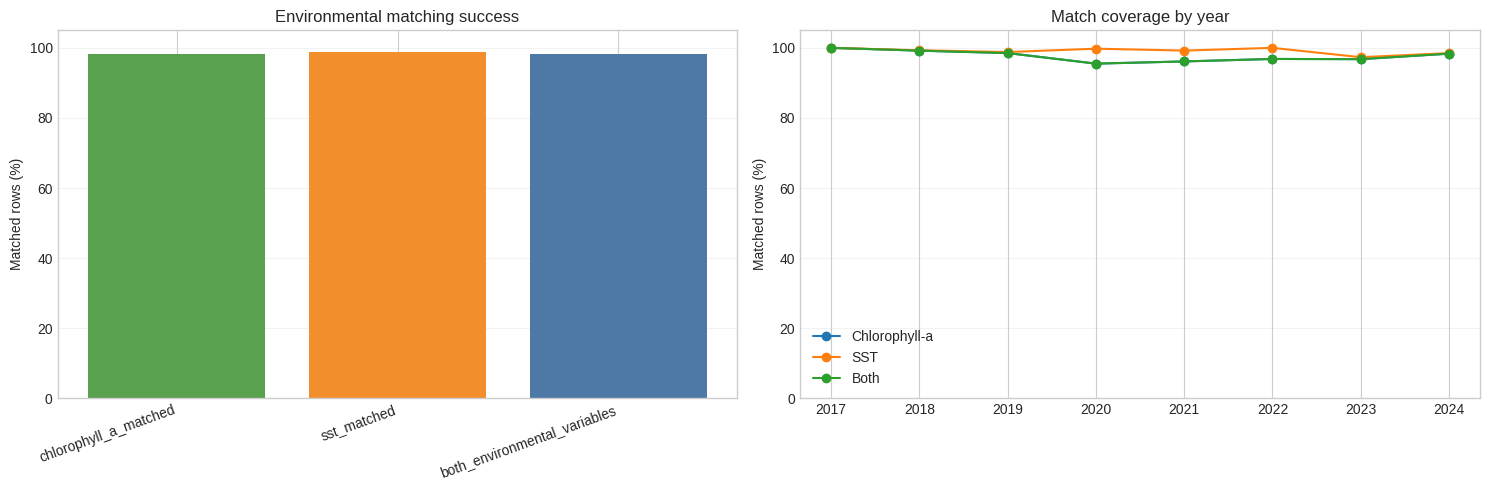

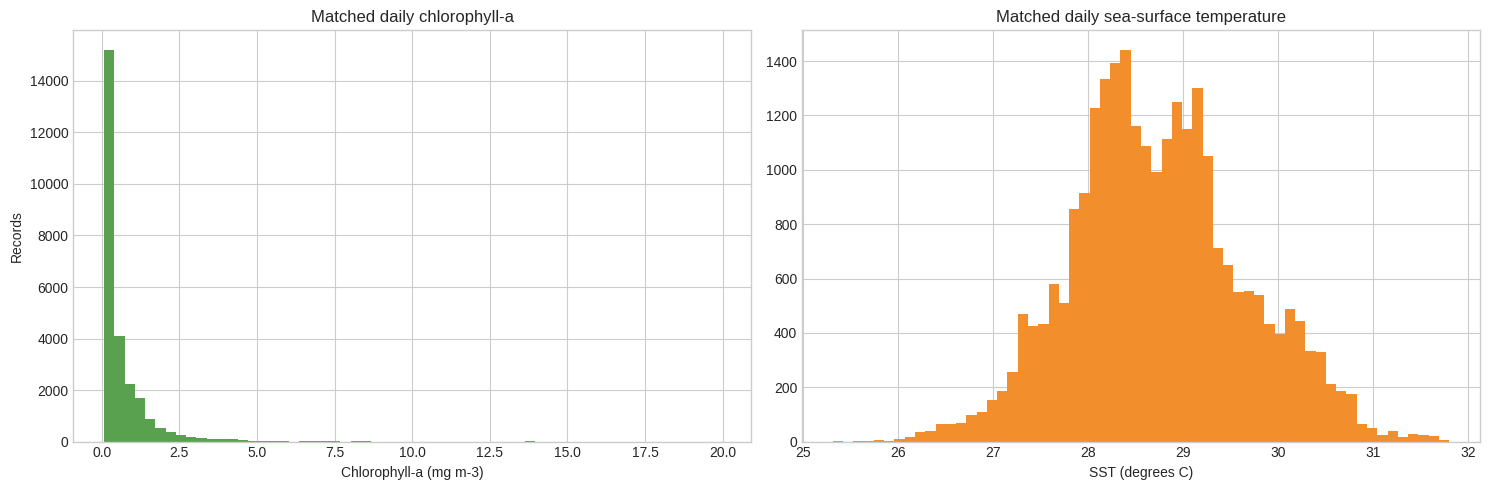

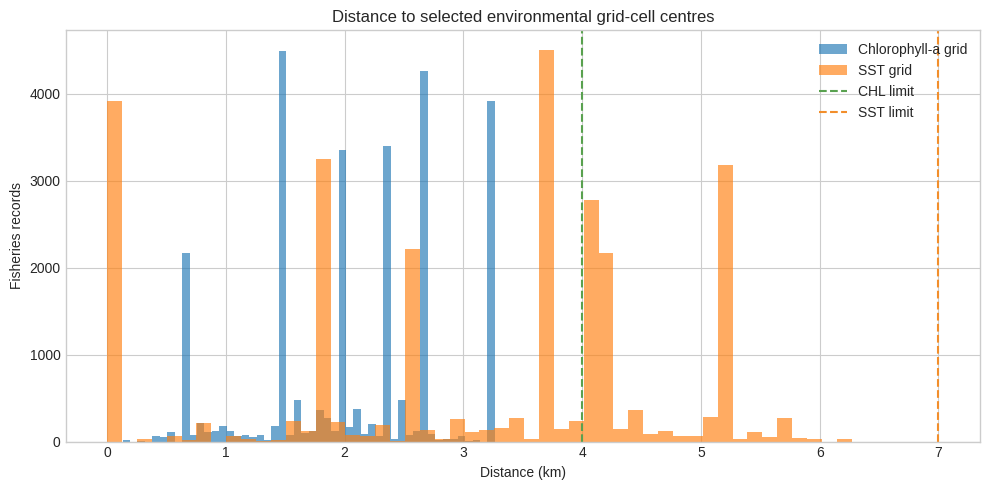

In [9]:
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes[0].bar(summary.metric.iloc[1:],summary.percent.iloc[1:],color=['#59a14f','#f28e2b','#4e79a7']); axes[0].set_ylim(0,105); axes[0].set_ylabel('Matched rows (%)'); axes[0].set_title('Environmental matching success'); plt.setp(axes[0].get_xticklabels(),rotation=20,ha='right')
axes[1].plot(yearly.year,yearly.chlorophyll_a_matches_percent,marker='o',label='Chlorophyll-a'); axes[1].plot(yearly.year,yearly.sst_matches_percent,marker='o',label='SST'); axes[1].plot(yearly.year,yearly.complete_matches_percent,marker='o',label='Both'); axes[1].set_ylim(0,105); axes[1].set_ylabel('Matched rows (%)'); axes[1].set_title('Match coverage by year'); axes[1].legend()
for ax in axes: ax.grid(axis='y',alpha=.25)
fig.tight_layout(); fig.savefig(FIGURE_DIR/'integration_match_coverage.png',dpi=200,bbox_inches='tight'); plt.show()
complete=integrated[integrated.environment_complete]
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes[0].hist(complete.chlorophyll_a_mg_m3,bins=60,color='#59a14f'); axes[0].set_title('Matched daily chlorophyll-a'); axes[0].set_xlabel('Chlorophyll-a (mg m-3)'); axes[0].set_ylabel('Records')
axes[1].hist(complete.sea_surface_temperature_c,bins=60,color='#f28e2b'); axes[1].set_title('Matched daily sea-surface temperature'); axes[1].set_xlabel('SST (degrees C)')
fig.tight_layout(); fig.savefig(FIGURE_DIR/'environmental_distributions.png',dpi=200,bbox_inches='tight'); plt.show()
fig,ax=plt.subplots(figsize=(10,5)); ax.hist(integrated.chlorophyll_a_mg_m3_distance_km,bins=50,alpha=.65,label='Chlorophyll-a grid'); ax.hist(integrated.sea_surface_temperature_c_distance_km,bins=50,alpha=.65,label='SST grid'); ax.axvline(4,color='#59a14f',linestyle='--',label='CHL limit'); ax.axvline(7,color='#f28e2b',linestyle='--',label='SST limit'); ax.set_title('Distance to selected environmental grid-cell centres'); ax.set_xlabel('Distance (km)'); ax.set_ylabel('Fisheries records'); ax.legend(); fig.tight_layout(); fig.savefig(FIGURE_DIR/'spatial_match_distances.png',dpi=200,bbox_inches='tight'); plt.show()

## 8. Save integrated artifacts and manifest

In [11]:
all_path=PROCESSED_DIR/'fisheries_environment_integrated_all.parquet'
complete_path=PROCESSED_DIR/'fisheries_environment_integrated_complete.parquet'
integrated.to_parquet(all_path,index=False); integrated[integrated.environment_complete].to_parquet(complete_path,index=False)
manifest={'created_utc':pd.Timestamp.now(tz='UTC').isoformat(),'runtime':'Google Colab' if IN_COLAB else 'Local Windows','method':'exact calendar day plus independent nearest grid-cell centre','distance_limits_km':{'chlorophyll_a':4.0,'sst':7.0},'input_rows':len(fish),'output_rows_all':len(integrated),'output_rows_complete':int(integrated.environment_complete.sum()),'variables':{'chlorophyll_a':'CHL, milligram m-3','sst':'thetao surface layer, degrees_C'},'salinity_integrated':False,'outputs':[all_path.name,complete_path.name]}
with (EVIDENCE_DIR/'integration_manifest.json').open('w',encoding='utf-8') as f: json.dump(manifest,f,indent=2)
chl_ds.close(); sst_ds.close()
print('Saved:',all_path,complete_path,sep='/n')
print('Evidence:',EVIDENCE_DIR); print('Figures:',FIGURE_DIR)

Saved:/n/content/drive/MyDrive/FishGuard-C3/data/processed/fisheries_environment_integrated_all.parquet/n/content/drive/MyDrive/FishGuard-C3/data/processed/fisheries_environment_integrated_complete.parquet
Evidence: /content/drive/MyDrive/FishGuard-C3/outputs/audit/data_integration
Figures: /content/drive/MyDrive/FishGuard-C3/outputs/figures/data_integration


## Interpretation for the viva

The fisheries observations and environmental grids do not share identical coordinates. Nearest-cell matching therefore links each fishing event to the closest grid-cell centre independently in each dataset. Exact-day matching preserves temporal meaning. Match flags, selected grid coordinates, and distances make the process auditable. Missing chlorophyll-a—often caused by cloud coverage—remains missing rather than being interpreted as zero. Later feature engineering may evaluate leakage-safe historical windows, but this integration stage does not impute or use future observations.